In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
df = pd.read_csv("../data/processed/products_cleaned.csv")

In [44]:
df.head()

,id,title,category,price,discountPercentage,rating,stock,brand,availabilityStatus
0,1,Essence Mascara Lash Princess,beauty,9.99,10.48,2.56,99,Essence,In Stock
1,2,Eyeshadow Palette with Mirror,beauty,19.99,18.19,2.86,34,Glamour Beauty,In Stock
2,3,Powder Canister,beauty,14.99,9.84,4.64,89,Velvet Touch,In Stock
3,4,Red Lipstick,beauty,12.99,12.16,4.36,91,Chic Cosmetics,In Stock
4,5,Red Nail Polish,beauty,8.99,11.44,4.32,79,Nail Couture,In Stock


In [45]:
df.shape

(30, 9)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  30 non-null     int64  
 1   title               30 non-null     str    
 2   category            30 non-null     str    
 3   price               30 non-null     float64
 4   discountPercentage  30 non-null     float64
 5   rating              30 non-null     float64
 6   stock               30 non-null     int64  
 7   brand               15 non-null     str    
 8   availabilityStatus  30 non-null     str    
dtypes: float64(3), int64(2), str(4)
memory usage: 3.4 KB


In [47]:
print("Missing values:")
print(df.isna().sum())

Missing values:
id                     0
title                  0
category               0
price                  0
discountPercentage     0
rating                 0
stock                  0
brand                 15
availabilityStatus     0
dtype: int64


In [48]:
df["brand"] = df["brand"].fillna("Unknown")

In [52]:
df["brand"] = df["brand"].isna().sum()


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
print("Duplicate product IDs:", df["id"].duplicated().sum())

Duplicate product IDs: 0


In [10]:
df.describe(include="number")

,id,price,discountPercentage,rating,stock
count,30.000000,30.000000,30.000000,30.000000,30.000000
mean,15.500000,219.250000,9.839667,3.858333,54.933333
std,8.803408,570.491833,5.456157,0.714660,33.816883
min,1.000000,0.990000,0.160000,2.530000,3.000000
25%,8.250000,5.115000,8.600000,3.285000,27.500000
50%,15.500000,11.990000,10.375000,3.950000,59.000000
75%,22.750000,77.490000,14.217500,4.367500,87.500000
max,30.000000,2499.990000,19.090000,4.930000,99.000000


In [11]:
df.describe(include="object")

C:\Users\rajku\AppData\Local\Temp\ipykernel_6232\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,title,category,brand,availabilityStatus
count,30,30,30,30
unique,30,4,15,2
top,Essence Mascara Lash Princess,groceries,Unknown,In Stock
freq,1,15,15,27


In [12]:
print(df["category"].value_counts())

category
groceries     15
beauty         5
fragrances     5
furniture      5
Name: count, dtype: int64


In [13]:
print(df["availabilityStatus"].value_counts())

availabilityStatus
In Stock     27
Low Stock     3
Name: count, dtype: int64


In [14]:
print(df["brand"].value_counts(dropna=False))

brand
Unknown             15
Annibale Colombo     2
Essence              1
Glamour Beauty       1
Velvet Touch         1
Chic Cosmetics       1
Nail Couture         1
Calvin Klein         1
Chanel               1
Dior                 1
Dolce & Gabbana      1
Gucci                1
Furniture Co.        1
Knoll                1
Bath Trends          1
Name: count, dtype: int64


In [15]:
df.groupby("category")["price"].mean().sort_values(ascending=False)


category
furniture     1199.990000
fragrances      83.990000
beauty          13.390000
groceries        6.043333
Name: price, dtype: float64

In [16]:
df.groupby("category")["stock"].sum().sort_values(ascending=False)

category
groceries     731
beauty        392
fragrances    280
furniture     245
Name: stock, dtype: int64

In [17]:
df.groupby("category")["rating"].mean().sort_values(ascending=False)

category
furniture     4.006000
groceries     3.856667
fragrances    3.826000
beauty        3.748000
Name: rating, dtype: float64

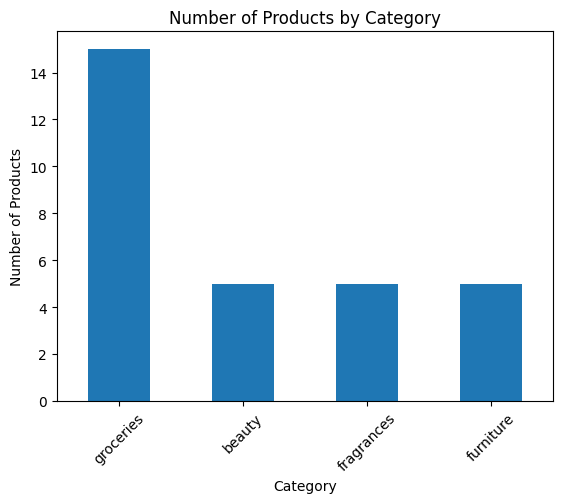

In [18]:
df["category"].value_counts().plot(kind="bar")

plt.title("Number of Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

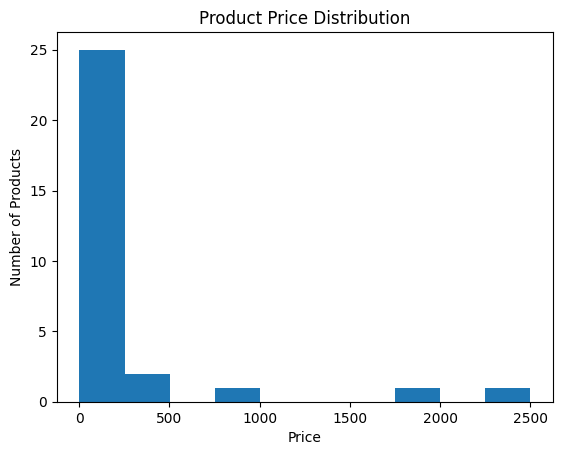

In [19]:
df["price"].plot(kind="hist", bins=10)

plt.title("Product Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

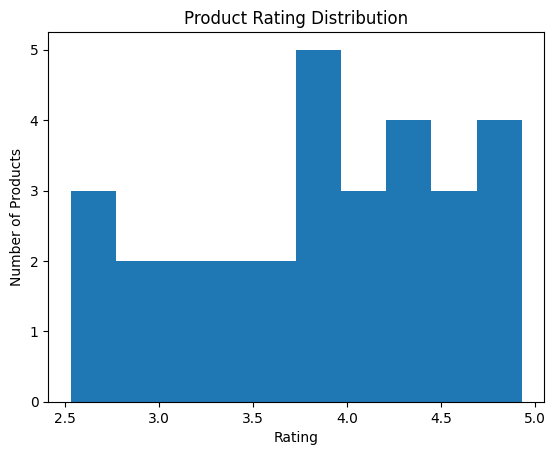

In [20]:
df["rating"].plot(kind="hist", bins=10)

plt.title("Product Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

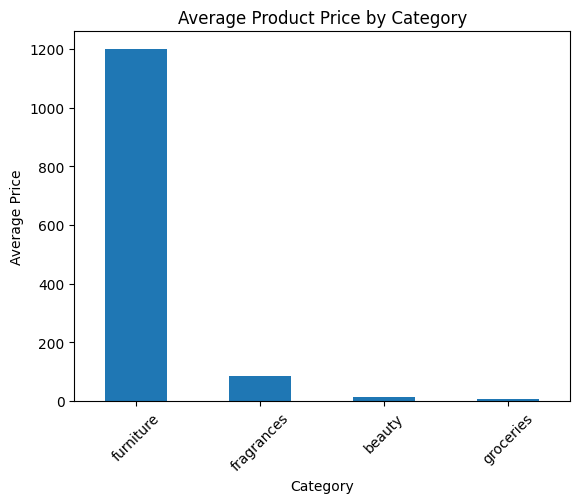

In [21]:
category_price = df.groupby("category")["price"].mean().sort_values(ascending=False)

category_price.plot(kind="bar")

plt.title("Average Product Price by Category")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

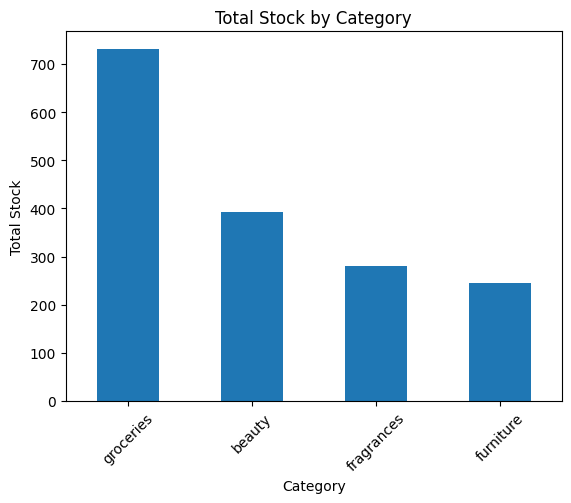

In [22]:
category_stock = df.groupby("category")["stock"].sum().sort_values(ascending=False)

category_stock.plot(kind="bar")

plt.title("Total Stock by Category")
plt.xlabel("Category")
plt.ylabel("Total Stock")
plt.xticks(rotation=45)
plt.show()

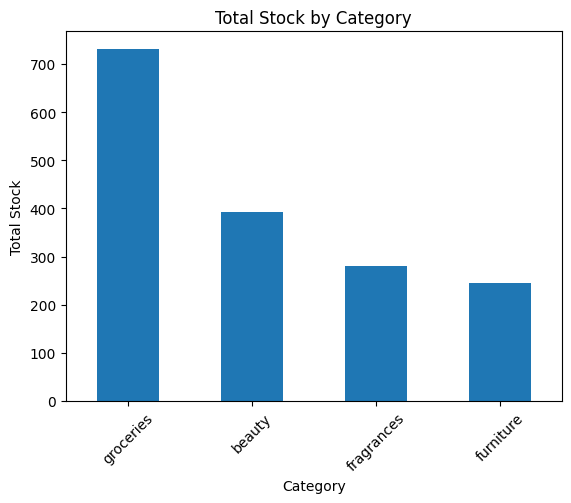

In [23]:
category_stock = df.groupby("category")["stock"].sum().sort_values(ascending=False)

category_stock.plot(kind="bar")

plt.title("Total Stock by Category")
plt.xlabel("Category")
plt.ylabel("Total Stock")
plt.xticks(rotation=45)
plt.show()

In [24]:
df["category"].value_counts()

category
groceries     15
beauty         5
fragrances     5
furniture      5
Name: count, dtype: int64

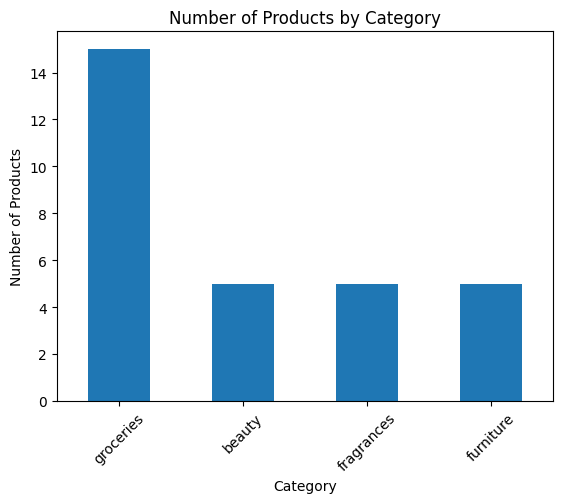

In [25]:
df["category"].value_counts().plot(kind="bar")

plt.title("Number of Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()

In [26]:
availability_count = df["availabilityStatus"].value_counts()

print(availability_count)

availabilityStatus
In Stock     27
Low Stock     3
Name: count, dtype: int64


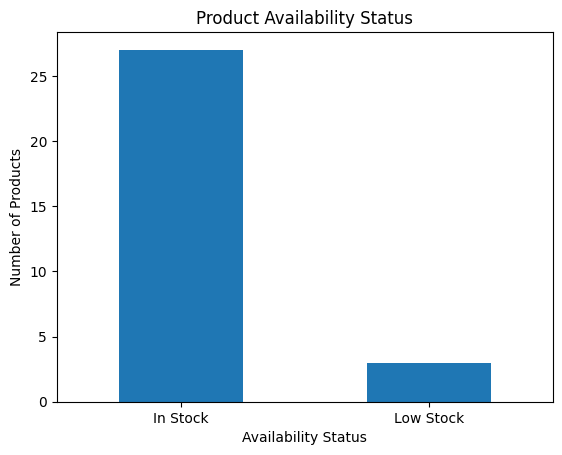

In [27]:
availability_count.plot(kind="bar")

plt.title("Product Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)
plt.show()

In [28]:
category_price = (
    df.groupby("category")["price"]
      .mean()
      .sort_values(ascending=False)
)

print(category_price)

category
furniture     1199.990000
fragrances      83.990000
beauty          13.390000
groceries        6.043333
Name: price, dtype: float64


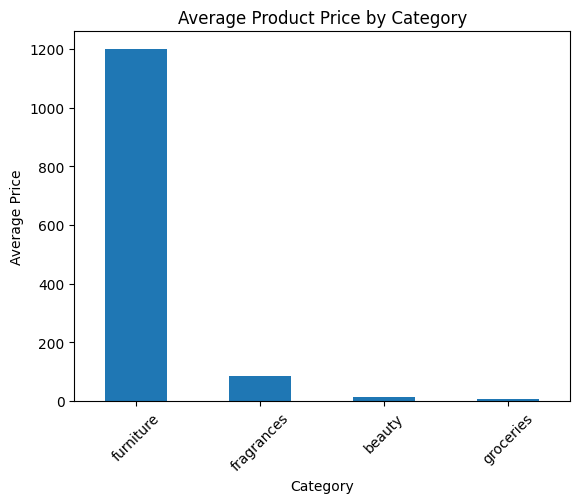

In [29]:
category_price.plot(kind="bar")

plt.title("Average Product Price by Category")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

In [30]:
category_rating = (
    df.groupby("category")["rating"]
      .mean()
      .sort_values(ascending=False)
)

print(category_rating)

category
furniture     4.006000
groceries     3.856667
fragrances    3.826000
beauty        3.748000
Name: rating, dtype: float64


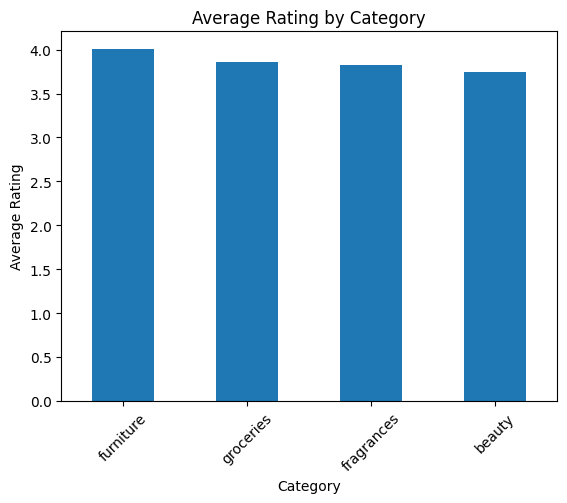

In [31]:
category_rating.plot(kind="bar")

plt.title("Average Rating by Category")
plt.xlabel("Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.show()

In [32]:
category_discount = (
    df.groupby("category")["discountPercentage"]
      .mean()
      .sort_values(ascending=False)
)

print(category_discount)

category
beauty        12.422000
furniture     10.574000
fragrances     9.626000
groceries      8.805333
Name: discountPercentage, dtype: float64


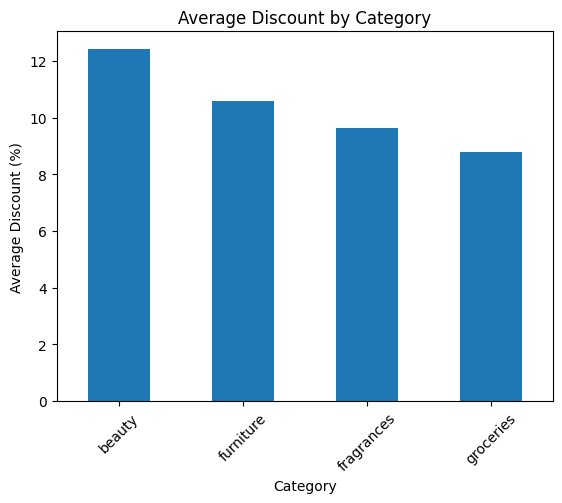

In [33]:
category_discount.plot(kind="bar")

plt.title("Average Discount by Category")
plt.xlabel("Category")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=45)
plt.show()

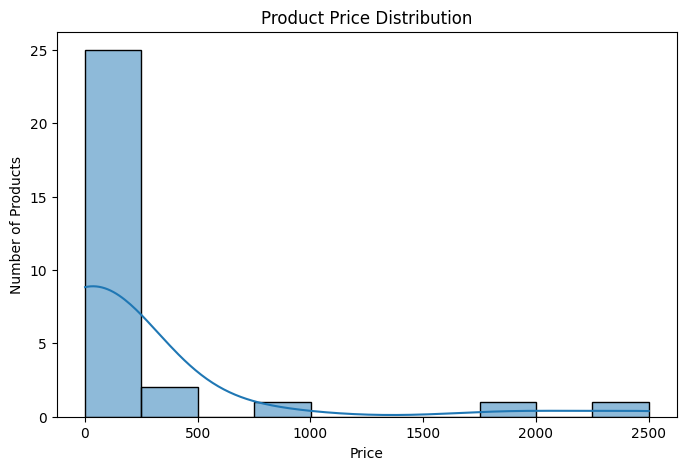

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(df["price"], bins=10, kde=True)

plt.title("Product Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

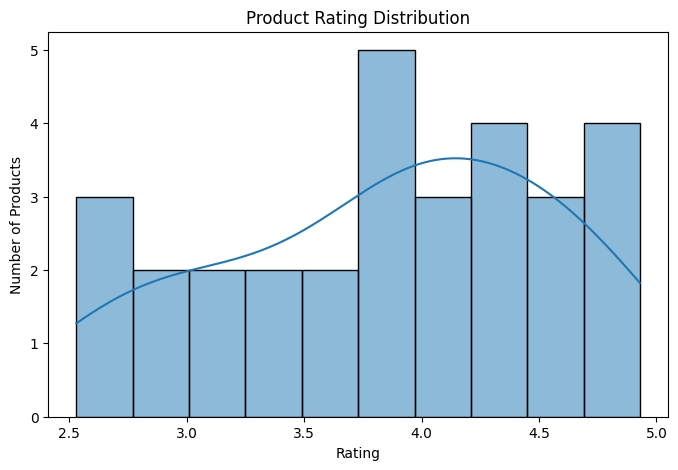

In [35]:
plt.figure(figsize=(8, 5))

sns.histplot(df["rating"], bins=10, kde=True)

plt.title("Product Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

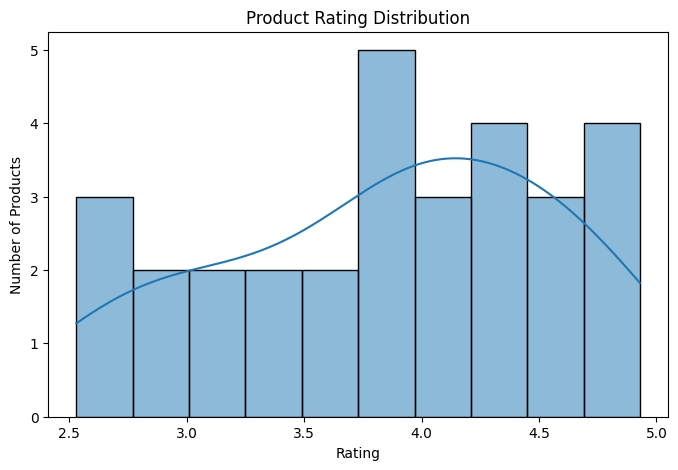

In [36]:
plt.figure(figsize=(8, 5))

sns.histplot(df["rating"], bins=10, kde=True)

plt.title("Product Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

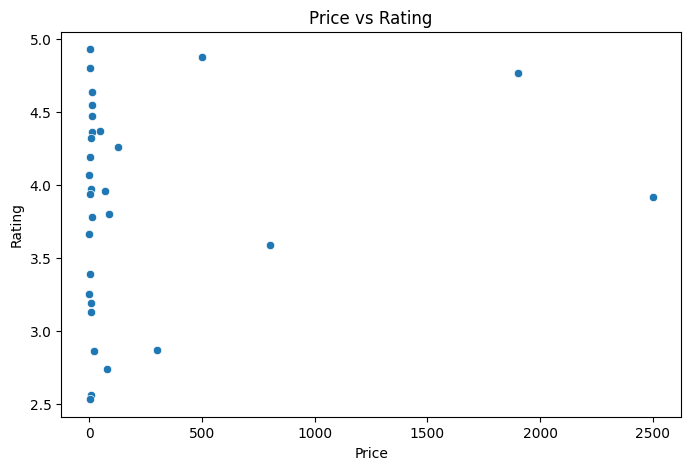

In [37]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="price",
    y="rating"
)

plt.title("Price vs Rating")
plt.xlabel("Price")
plt.ylabel("Rating")
plt.show()

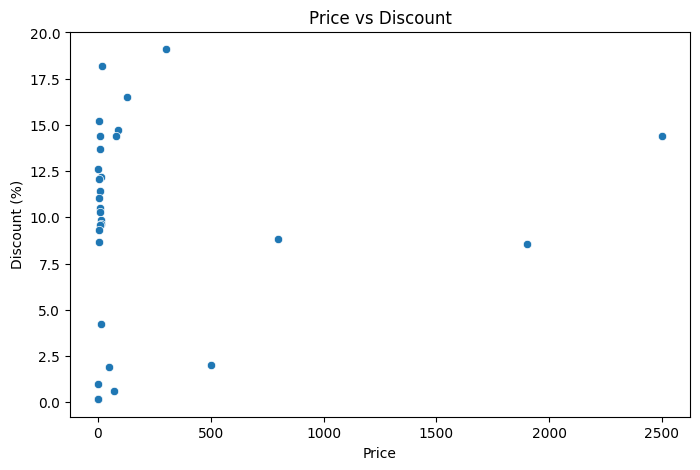

In [38]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="price",
    y="discountPercentage"
)

plt.title("Price vs Discount")
plt.xlabel("Price")
plt.ylabel("Discount (%)")
plt.show()

In [54]:
df.to_csv("output_file", index=False)